# Experiment 003 – How the data was made, and the real ceiling of Task 1

| | |
|---|---|
| **Task** | Task 1 – anti-cheat pre-filter, target `is_cheater` |
| **Metric** | F2 = 5·P·R / (4P + R) – recall counts 4× more than precision |
| **Baseline** | Experiment 002: blend, nested OOF F2 **0.8382**, test-like F2 0.8518 |
| **Question** | Experiment 002 gained only +0.002 over 001. Is there more signal to find, or are we at the ceiling? |

Plan:

1. Study how the synthetic data was generated (section 3). Look for leaks, hidden structure, and where the model loses F2.
2. Measure the learning curve – does more data still help?
3. Test each idea from that research on the same folds (section 5): feature drop, generator-aware features,
   test-like training weights, pseudo-labels on the unlabeled **train** rows.
4. Tune LightGBM on the kept features and average the best configs over seeds (sections 6–7).

Protocol: same as experiment 002 – 5-fold `StratifiedKFold` (seed 42), nested F2 (threshold tuned on the other folds),
and test-like F2 (validation folds re-masked to the test NaN rates). The test set is used only for its NaN rates and for the final prediction.

## 0. Setup

In [1]:
import json
import time
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import average_precision_score, fbeta_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold

Paths and constants. `N_JOBS = 4`: this laptop has 4 physical cores, and LightGBM with 8 threads on WSL is about 20× slower.

In [2]:
EXPERIMENT = "003"
TASK_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = TASK_DIR / "data"
ASSETS_DIR = TASK_DIR / "assets" / "experiments" / EXPERIMENT
PRED_DIR = TASK_DIR / "predictions" / "experiments" / EXPERIMENT
MODEL_DIR = TASK_DIR / "models" / "experiments" / EXPERIMENT
for d in (ASSETS_DIR, PRED_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

TARGET = "is_cheater"
ID_COL = "player_id"
SEED = 42
N_FOLDS = 5
N_JOBS = 4

Plot style and figure helper (PNG, 300 dpi, tight box).

In [3]:
CLASS_COLORS = {"Legit": "#2a78d6", "Cheater": "#eb6834"}
MAIN, NEUTRAL = "#eb6834", "#b5b4ae"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "grid.color": "#e6e6e6", "axes.titleweight": "bold"})
pd.set_option("display.float_format", "{:.4f}".format)


def save_fig(fig, name):
    path = ASSETS_DIR / f"{name}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"saved {path.relative_to(TASK_DIR)}")

## 1. Data

Load train and test. Labeled train rows are for fitting. The 13,184 unlabeled train rows are used only in the pseudo-label test (they are train rows, not test rows).

In [4]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
FEATURES = [c for c in train.columns if c not in (ID_COL, TARGET)]
assert list(test.columns) == [ID_COL, *FEATURES]

lab = train.dropna(subset=[TARGET]).reset_index(drop=True)
unl = train[train[TARGET].isna()].reset_index(drop=True)
X = lab[FEATURES]
y = lab[TARGET].astype(int).to_numpy()
print(f"labeled {len(lab):,}  unlabeled {len(unl):,}  test {len(test):,}  cheater rate {y.mean():.3f}")

labeled 90,816  unlabeled 13,184  test 25,889  cheater rate 0.349


Same folds as experiments 001 and 002.

In [5]:
fold_id = np.empty(len(y), dtype=int)
for k, (_, val_idx) in enumerate(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(X, y)):
    fold_id[val_idx] = k
np.bincount(fold_id)

array([18164, 18163, 18163, 18163, 18163])

## 2. Metrics and test-like validation

Same helpers as experiment 002: F2 curve over all distinct thresholds (optional row weights) and nested F2.

In [6]:
def f2_curve(y_true, proba, weight=None):
    w = np.ones(len(y_true)) if weight is None else np.asarray(weight, dtype=float)
    order = np.argsort(-proba, kind="stable")
    yt, p, w = y_true[order], proba[order], w[order]
    tp, fp, pos = np.cumsum(w * yt), np.cumsum(w * (1 - yt)), (w * yt).sum()
    last = np.r_[p[1:] != p[:-1], True]
    tp, fp, thr = tp[last], fp[last], p[last]
    return thr, 5 * tp / (5 * tp + 4 * (pos - tp) + fp), tp / (tp + fp), tp / pos


def best_threshold(y_true, proba, weight=None):
    thr, f2, _, _ = f2_curve(y_true, proba, weight)
    i = np.argmax(f2)
    return thr[i], f2[i]


def nested_f2(y_true, proba, weight=None):
    w = np.ones(len(y_true)) if weight is None else weight
    pred = np.zeros(len(y_true), dtype=int)
    for k in range(N_FOLDS):
        inside = fold_id != k
        t, _ = best_threshold(y_true[inside], proba[inside], w[inside])
        pred[~inside] = proba[~inside] >= t
    return fbeta_score(y_true, pred, beta=2, sample_weight=w)

Test-like copy of the validation folds, built exactly as in experiment 002: extra random masking where test has more NaNs, importance weights where test has fewer. Only test NaN rates are used.

In [7]:
p_train = X.isna().mean().to_numpy()
p_test = test[FEATURES].isna().mean().to_numpy()
up = p_test > p_train
rng = np.random.default_rng(SEED)
extra_mask = (rng.random(X.shape) < np.where(up, (p_test - p_train) / (1 - p_train), 0)) & X.notna().to_numpy()
X_testlike = X.mask(extra_mask)
log_w = np.where(X.isna().to_numpy(), np.log(p_test / p_train), np.log((1 - p_test) / (1 - p_train)))[:, ~up].sum(axis=1)
w_testlike = np.exp(log_w - log_w.max())
w_testlike /= w_testlike.mean()
print(f"effective sample size of the test-like weights: {w_testlike.sum() ** 2 / (w_testlike ** 2).sum():,.0f}")

effective sample size of the test-like weights: 21,330


## 3. Research: how the data was generated

Checks run before this notebook found **no leaks**: `player_id`, row order, the per-row NaN count, and the float
precision of each value all have no relation to the label (AUC 0.498–0.502). Integer-valued floats only appear at clip bounds.
There is also no label noise: rows in a class-only range are 100% one class.

So the remaining question is the shape of the class densities. Cheater rate per fine bin for the five strongest features:

saved assets/experiments/003/block-structure.png


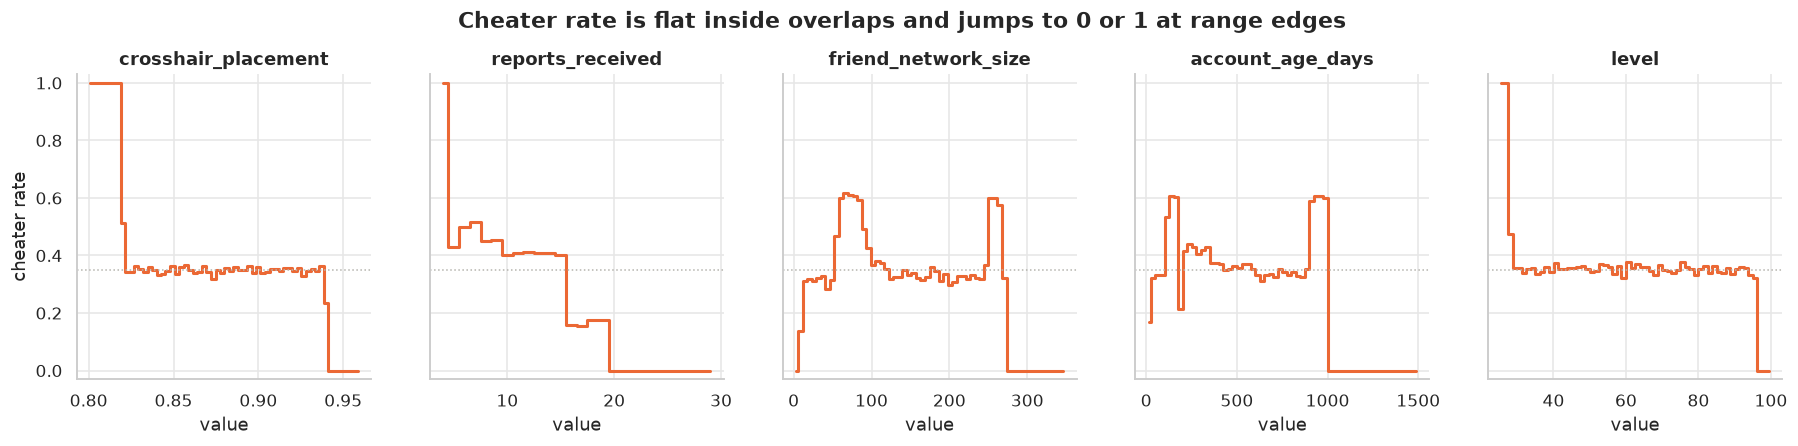

In [8]:
BLOCK = ["crosshair_placement", "reports_received", "friend_network_size", "account_age_days", "level"]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6), sharey=True)
for ax, f in zip(axes, BLOCK):
    v = lab[f]
    edges = np.arange(v.min() - 0.5, v.max() + 1.5, 1) if f == "reports_received" else np.linspace(v.min(), v.max(), 61)
    b = pd.cut(v, edges, include_lowest=True)
    rate = lab.groupby(b, observed=True)[TARGET].mean()
    mids = [iv.mid for iv in rate.index]
    ax.step(mids, rate.to_numpy(), where="mid", color=MAIN, linewidth=2)
    ax.axhline(y.mean(), color=NEUTRAL, linestyle=":", linewidth=1)
    ax.set(title=f, xlabel="value", ylim=(-0.03, 1.03))
axes[0].set_ylabel("cheater rate")
fig.suptitle("Cheater rate is flat inside overlaps and jumps to 0 or 1 at range edges", fontweight="bold", y=1.04)
save_fig(fig, "block-structure")
plt.show()

The class densities are **piecewise uniform**. Each class mixes a few hidden player types, and each type draws
these features from flat ranges. Example: `crosshair_placement` is U(0.82, 0.96) for legit and U(0.80, 0.94) for cheaters.
Below 0.82 every player is a cheater, above 0.94 every player is legit, and in between the rate is a flat 35%.
Inside an overlap the value carries **no information**. The skill features (K/D, headshot, accuracy …) are bell-shaped with a
small class shift, and 16 features have the same distribution in both classes (pure noise).

`level_progression_speed` is built from other columns: `lps · age / level` is U(0.15, 1.08) in **both** classes.
So it only helps when `account_age_days` or `level` is missing:

In [9]:
mult = lab["level_progression_speed"] * lab["account_age_days"] / lab["level"]
mult.groupby(lab[TARGET]).describe()[["count", "mean", "std", "min", "max"]]

,count,mean,std,min,max
is_cheater,,,,,
0.0000,43076.0000,0.6149,0.2680,0.1500,1.0800
1.0000,23188.0000,0.6159,0.2677,0.1502,1.0800


### Learning curve
Does more training data still help? Same LightGBM (1,023 bins, 300 trees) trained on a random share of each training fold.

In [10]:
LC_PARAMS = dict(n_estimators=300, learning_rate=0.06, num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1,
                 colsample_bytree=0.7, max_bin=1023, min_data_in_bin=1, verbose=-1, n_jobs=N_JOBS)
lc_rng = np.random.default_rng(0)
lc_rows = []
for frac in [0.25, 0.5, 1.0]:
    oof = np.zeros(len(y))
    for k in range(N_FOLDS):
        trn = np.where(fold_id != k)[0]
        trn = lc_rng.choice(trn, int(len(trn) * frac), replace=False)
        val = fold_id == k
        oof[val] = lgb.LGBMClassifier(**LC_PARAMS).fit(X.iloc[trn], y[trn]).predict_proba(X[val])[:, 1]
    lc_rows.append({"train_share": frac, "train_rows": int(len(y) * 0.8 * frac),
                    "roc_auc": roc_auc_score(y, oof), "best_f2": best_threshold(y, oof)[1]})
    print(lc_rows[-1])
lc = pd.DataFrame(lc_rows)
lc.to_csv(ASSETS_DIR / "learning-curve.csv", index=False)

{'train_share': 0.25, 'train_rows': 18163, 'roc_auc': 0.8830035670830738, 'best_f2': np.float64(0.8326900189777735)}


{'train_share': 0.5, 'train_rows': 36326, 'roc_auc': 0.8885395629790804, 'best_f2': np.float64(0.835986701624456)}


{'train_share': 1.0, 'train_rows': 72652, 'roc_auc': 0.89134967972026, 'best_f2': np.float64(0.8380554727110051)}


saved assets/experiments/003/learning-curve.png


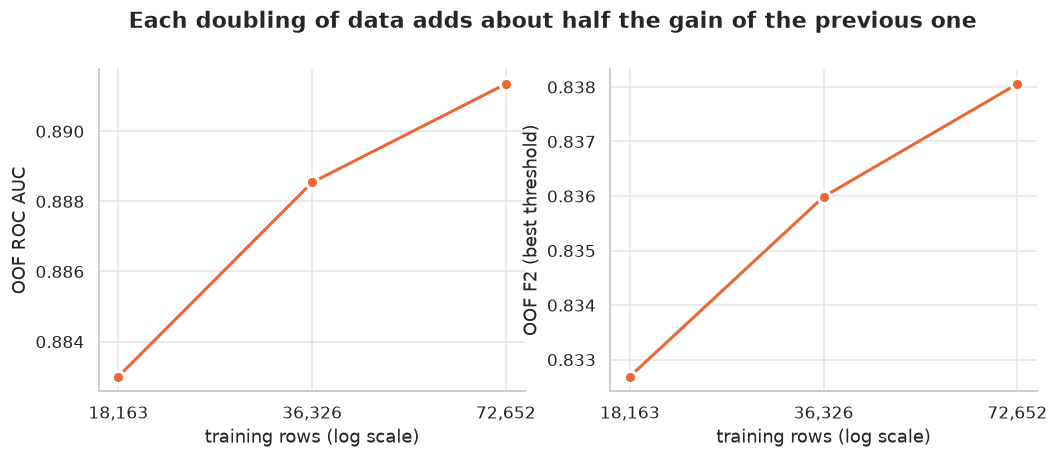

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col, label in zip(axes, ["roc_auc", "best_f2"], ["OOF ROC AUC", "OOF F2 (best threshold)"]):
    ax.plot(lc["train_rows"], lc[col], "o-", color=MAIN, linewidth=2, markersize=8, markeredgecolor="white", markeredgewidth=2)
    ax.set_xscale("log", base=2)
    ax.set_xticks(lc["train_rows"], [f"{r:,}" for r in lc["train_rows"]])
    ax.set(xlabel="training rows (log scale)", ylabel=label)
fig.suptitle("Each doubling of data adds about half the gain of the previous one", fontweight="bold", y=1.02)
save_fig(fig, "learning-curve")
plt.show()

### Where the F2 is lost
Experiment 002 blend OOF predictions, split by how many of the five block features a row has observed.

In [12]:
oof_002 = pd.read_csv(TASK_DIR / "predictions" / "experiments" / "002" / "oof.csv")
assert (oof_002[ID_COL].to_numpy() == lab[ID_COL].to_numpy()).all()
p002 = oof_002["oof_Blend"].to_numpy()
t002, _ = best_threshold(y, p002)
n_obs = X[BLOCK].notna().sum(axis=1)
err = pd.DataFrame({"n_obs": n_obs, "y": y, "p": p002, "flag": p002 >= t002}).groupby("n_obs").apply(
    lambda d: pd.Series({"rows": len(d), "roc_auc": roc_auc_score(d.y, d.p) if d.y.nunique() > 1 else np.nan,
                         "false_neg": ((d.y == 1) & ~d.flag).sum(), "false_pos": ((d.y == 0) & d.flag).sum()}))
err["share_train"] = err["rows"] / len(y)
err["share_test"] = test[BLOCK].notna().sum(axis=1).value_counts(normalize=True).reindex(err.index).fillna(0)
err.to_csv(ASSETS_DIR / "error-by-observed-block-features.csv")
err

,rows,roc_auc,false_neg,false_pos,share_train,share_test
n_obs,,,,,,
0,3.0000,1.0000,0.0000,1.0000,0.0000,0.0000
1,185.0000,0.6902,2.0000,97.0000,0.0020,0.0000
2,2376.0000,0.7888,12.0000,1047.0000,0.0262,0.0004
3,13593.0000,0.8432,119.0000,5112.0000,0.1497,0.0163
4,36698.0000,0.8847,307.0000,11114.0000,0.4041,0.2114
5,37961.0000,0.9214,345.0000,9237.0000,0.4180,0.7719


In [13]:
bands = pd.cut(p002, [0, 0.01, 0.1, 0.19, 0.3, 0.5, 0.7, 0.9, 1.0], include_lowest=True)
pd.DataFrame({"rows": pd.Series(bands).value_counts(sort=False),
              "cheater_rate": pd.Series(y).groupby(bands, observed=True).mean()})

,rows,cheater_rate
"(-0.001, 0.01]",22446,0.0000
"(0.01, 0.1]",4403,0.0152
"(0.1, 0.19]",6339,0.1118
"(0.19, 0.3]",10041,0.2480
"(0.3, 0.5]",23549,0.4017
"(0.5, 0.7]",10204,0.5784
"(0.7, 0.9]",4432,0.8375
"(0.9, 1.0]",9402,0.9982


- Rows with all five block features observed reach AUC ≈ 0.92; rows with three reach ≈ 0.84.
  **77% of test rows** have all five observed, vs 42% of train rows, so test scores higher than CV.
- About 23,500 rows score 0.3–0.5 with a flat ~40% cheater rate. These players sit inside the overlap of every range, so
  no feature can separate them. At the F2 threshold (≈ 0.19) all of them get flagged. This is irreducible (Bayes) error.

## 4. Cross-validation runner

`run_cv` fits one model per fold and scores normal and test-like OOF predictions. Options:
`fe` (stateless feature function), `weight` (training row weights), `extra` (extra training rows per fold, fitted on that fold only).

In [14]:
BASE_PARAMS = dict(n_estimators=341, learning_rate=0.0242, num_leaves=41, min_child_samples=7, min_split_gain=0.369,
                   colsample_bytree=0.874, subsample=0.777, subsample_freq=1, reg_lambda=4.44)  # experiment 002 tuned


def lgbm(params, seed=SEED, max_bin=1023):
    return lgb.LGBMClassifier(**params, max_bin=max_bin, min_data_in_bin=1, random_state=seed, verbose=-1, n_jobs=N_JOBS)


def score(name, oof, oof_tl, seconds=np.nan):
    return {"model": name, "roc_auc": roc_auc_score(y, oof), "pr_auc": average_precision_score(y, oof),
            "nested_f2": nested_f2(y, oof), "threshold": best_threshold(y, oof)[0],
            "testlike_auc": roc_auc_score(y, oof_tl, sample_weight=w_testlike),
            "testlike_f2": nested_f2(y, oof_tl, w_testlike), "fit_seconds": seconds}


def run_cv(name, make_model, fe=lambda f: f, weight=None, extra=None):
    A, A_tl = fe(X), fe(X_testlike)
    oof, oof_tl = np.zeros(len(y)), np.zeros(len(y))
    start = time.perf_counter()
    for k in range(N_FOLDS):
        trn, val = fold_id != k, fold_id == k
        Xt, yt = A[trn], y[trn]
        wt = np.ones(trn.sum()) if weight is None else weight[trn]
        if extra is not None:
            Xe, ye, we = extra(k)
            Xt, yt, wt = pd.concat([Xt, fe(Xe)], ignore_index=True), np.r_[yt, ye], np.r_[wt, we]
        model = make_model().fit(Xt, yt, sample_weight=wt)
        oof[val] = model.predict_proba(A[val])[:, 1]
        oof_tl[val] = model.predict_proba(A_tl[val])[:, 1]
    row = score(name, oof, oof_tl, time.perf_counter() - start)
    print(f"{name:44s} AUC {row['roc_auc']:.4f}  nested F2 {row['nested_f2']:.4f}  test-like F2 {row['testlike_f2']:.4f}  ({row['fit_seconds']:.0f}s)")
    return oof, oof_tl, row

## 5. Ideas from the research, one at a time

Baseline: experiment 002 tuned LightGBM, one seed, 1,023 bins, all 31 features.

In [15]:
_, _, row = run_cv("baseline (exp 002 params, 31 features)", lambda: lgbm(BASE_PARAMS))
ablation = [row]

baseline (exp 002 params, 31 features)       AUC 0.8929  nested F2 0.8383  test-like F2 0.8506  (20s)


**Drop the noise features.** Keep the 15 features with a class difference: the 5 block features, `level_progression_speed`, and 9 skill features.

In [16]:
KEEP = ["reports_received", "crosshair_placement", "friend_network_size", "account_age_days", "level",
        "level_progression_speed", "game_sense_score", "headshot_percentage", "kill_death_ratio", "accuracy_score",
        "aiming_smoothness", "win_rate", "spray_control_score", "kill_consistency", "reaction_time_ms"]
keep = lambda f: f[KEEP]
_, _, row = run_cv("keep 15 features", lambda: lgbm(BASE_PARAMS), fe=keep)
ablation.append(row)

keep 15 features                             AUC 0.8934  nested F2 0.8380  test-like F2 0.8513  (14s)


**Generator-aware ranges.** From `lps = level · U(0.15, 1.08) / age`: the possible range of age given level and lps, and of level given age and lps. Trees cannot build these ratios by themselves.

In [17]:
def with_ranges(f):
    out = f[KEEP].copy()
    r = out["level"] / out["level_progression_speed"]
    out["age_lo"], out["age_hi"] = 0.15 * r, 1.08 * r
    out["age_filled"] = out["account_age_days"].fillna(0.615 * r)
    s = out["level_progression_speed"] * out["account_age_days"]
    out["level_lo"], out["level_hi"] = s / 1.08, s / 0.15
    return out


_, _, row = run_cv("keep 15 + age/level ranges from lps", lambda: lgbm(BASE_PARAMS), fe=with_ranges)
ablation.append(row)

keep 15 + age/level ranges from lps          AUC 0.8940  nested F2 0.8386  test-like F2 0.8508  (17s)


**Test-like training weights.** Weight training rows by how test-like their NaN pattern is, so the model spends its capacity on rows like the test rows.

In [18]:
_, _, row = run_cv("keep 15 + test-like training weights", lambda: lgbm(BASE_PARAMS), fe=keep, weight=w_testlike)
ablation.append(row)

keep 15 + test-like training weights         AUC 0.8886  nested F2 0.8368  test-like F2 0.8496  (13s)


**Soft pseudo-labels** on the 13,184 unlabeled **train** rows. A model fitted on the training fold predicts p for each one; the row is added twice, as a cheater with weight p and as legit with weight 1 − p.

In [19]:
def pseudo_rows(k):
    trn = fold_id != k
    p = lgbm(BASE_PARAMS).fit(X.loc[trn, KEEP], y[trn]).predict_proba(unl[KEEP])[:, 1]
    rows = pd.concat([unl[FEATURES], unl[FEATURES]], ignore_index=True)
    return rows, np.r_[np.ones(len(unl)), np.zeros(len(unl))].astype(int), np.r_[p, 1 - p]


_, _, row = run_cv("keep 15 + soft pseudo-labels", lambda: lgbm(BASE_PARAMS), fe=keep, extra=pseudo_rows)
ablation.append(row)

keep 15 + soft pseudo-labels                 AUC 0.8932  nested F2 0.8387  test-like F2 0.8514  (28s)


In [20]:
ablation_df = pd.DataFrame(ablation).set_index("model")
for col in ["nested_f2", "testlike_f2"]:
    ablation_df[f"delta_{col}"] = ablation_df[col] - ablation_df[col].iloc[0]
ablation_df.to_csv(ASSETS_DIR / "ablation.csv")
ablation_df[["roc_auc", "nested_f2", "delta_nested_f2", "testlike_f2", "delta_testlike_f2"]]

,roc_auc,nested_f2,delta_nested_f2,testlike_f2,delta_testlike_f2
model,,,,,
"baseline (exp 002 params, 31 features)",0.8929,0.8383,0.0000,0.8506,0.0000
keep 15 features,0.8934,0.8380,-0.0003,0.8513,0.0007
keep 15 + age/level ranges from lps,0.8940,0.8386,0.0003,0.8508,0.0001
keep 15 + test-like training weights,0.8886,0.8368,-0.0015,0.8496,-0.0011
keep 15 + soft pseudo-labels,0.8932,0.8387,0.0004,0.8514,0.0007


Only the feature drop helps. The fold-to-fold std of F2 is about 0.0014, so the other changes are noise or worse.

**Probe run outside this notebook (not kept):** a latent-class model (per class 8 + 4 components, histogram densities,
`level_progression_speed` left out to avoid double counting) reaches AUC 0.875 on its own. Its posteriors as stacking
features **lower** nested F2 to 0.8327. A GPU XGBoost run (GTX 1650 Ti) was not faster than CPU LightGBM here.

## 6. Tuning LightGBM on the 15 kept features

Optuna (TPE, seed 42), objective OOF ROC AUC, 4,095 bins, search space extended with `path_smooth` and `extra_trees`.
Trial 0 is the experiment 002 setting. The search ran for 17 trials and stopped on a flat plateau; set `RUN_TUNING = True`
to run it again (about 3 minutes per trial on this laptop). Otherwise the saved trials are loaded.

In [21]:
RUN_TUNING = False
TRIALS_PATH = ASSETS_DIR / "optuna-lightgbm-trials.csv"

if RUN_TUNING:
    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)

    def objective(trial):
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 300, 1500, log=True),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.06, log=True),
            "num_leaves": trial.suggest_int("num_leaves", 15, 127, log=True),
            "min_child_samples": trial.suggest_int("min_child_samples", 5, 200, log=True),
            "subsample": trial.suggest_float("subsample", 0.5, 1.0), "subsample_freq": 1,
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
            "min_split_gain": trial.suggest_float("min_split_gain", 0.0, 1.0),
            "path_smooth": trial.suggest_float("path_smooth", 0.0, 50.0),
            "extra_trees": trial.suggest_categorical("extra_trees", [False, True]),
        }
        oof = np.zeros(len(y))
        for k in range(N_FOLDS):
            trn, val = fold_id != k, fold_id == k
            oof[val] = lgbm(params, max_bin=4095).fit(X.loc[trn, KEEP], y[trn]).predict_proba(X.loc[val, KEEP])[:, 1]
        trial.set_user_attr("nested_f2", nested_f2(y, oof))
        print(f"trial {trial.number:2d}  AUC {roc_auc_score(y, oof):.4f}  nested F2 {trial.user_attrs['nested_f2']:.4f}")
        return roc_auc_score(y, oof)

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.enqueue_trial({k: v for k, v in BASE_PARAMS.items() if k != "subsample_freq"} | {"path_smooth": 0.0, "extra_trees": False})
    study.optimize(objective, n_trials=30)
    trials = pd.DataFrame([{"number": t.number, "roc_auc": t.value, "nested_f2": t.user_attrs["nested_f2"], **t.params}
                           for t in study.trials])
    trials.to_csv(TRIALS_PATH, index=False)
else:
    trials = pd.read_csv(TRIALS_PATH)
trials.sort_values("roc_auc", ascending=False).head(6)

,number,roc_auc,nested_f2,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,min_split_gain,path_smooth,extra_trees
0,0,0.8936,0.8381,341,0.0242,41,7,0.7770,0.8740,4.4400,0.3690,0.0000,False
16,16,0.8936,0.8391,348,0.0199,58,10,0.7311,0.6630,1.2285,0.0465,1.3769,False
15,15,0.8935,0.8379,320,0.0248,38,6,0.6880,0.7426,5.2238,0.1170,0.5640,False
9,9,0.8933,0.8377,1251,0.0233,19,67,0.8804,0.7368,2.8295,0.4938,26.1366,False
3,3,0.8932,0.8385,480,0.0193,39,89,0.5998,0.7085,0.4491,0.0465,30.3772,False
5,5,0.8932,0.8377,454,0.0328,29,32,0.7734,0.5109,21.9254,0.7751,46.9749,False


saved assets/experiments/003/optuna-trials.png


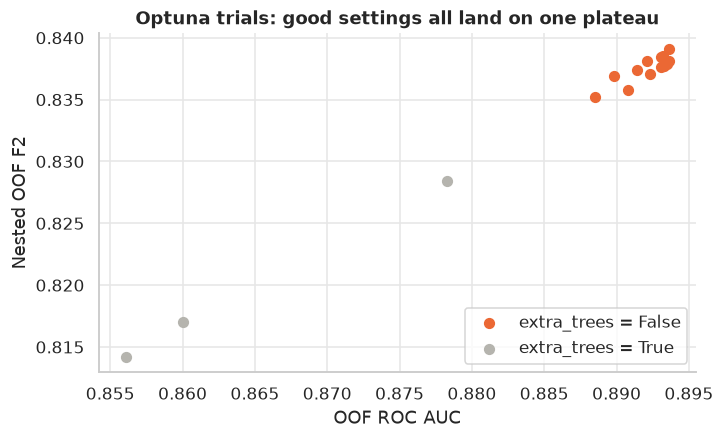

In [22]:
fig, ax = plt.subplots(figsize=(7, 4))
et = trials["extra_trees"].astype(bool)
ax.scatter(trials.loc[~et, "roc_auc"], trials.loc[~et, "nested_f2"], color=MAIN, s=40, label="extra_trees = False")
ax.scatter(trials.loc[et, "roc_auc"], trials.loc[et, "nested_f2"], color=NEUTRAL, s=40, label="extra_trees = True")
ax.set(title="Optuna trials: good settings all land on one plateau", xlabel="OOF ROC AUC", ylabel="Nested OOF F2")
ax.legend(loc="lower right")
save_fig(fig, "optuna-trials")
plt.show()

## 7. Final model: top-3 configs × 3 seeds

Average the probabilities of the three best trials by AUC, each with three seeds. Averaging lowers the variance that the learning curve shows is the main remaining error.

In [23]:
TOP = trials.sort_values("roc_auc", ascending=False).head(3)
PARAM_COLS = ["n_estimators", "learning_rate", "num_leaves", "min_child_samples", "subsample", "colsample_bytree",
              "reg_lambda", "min_split_gain", "path_smooth", "extra_trees"]
CONFIGS = []
for _, t in TOP.iterrows():
    p = {c: t[c] for c in PARAM_COLS}
    p.update(n_estimators=int(p["n_estimators"]), num_leaves=int(p["num_leaves"]),
             min_child_samples=int(p["min_child_samples"]), extra_trees=bool(p["extra_trees"]), subsample_freq=1)
    CONFIGS.append(p)
SEEDS = [42, 7, 2024]
print(json.dumps(CONFIGS, indent=1))

[
 {
  "n_estimators": 341,
  "learning_rate": 0.0242,
  "num_leaves": 41,
  "min_child_samples": 7,
  "subsample": 0.777,
  "colsample_bytree": 0.874,
  "reg_lambda": 4.44,
  "min_split_gain": 0.369,
  "path_smooth": 0.0,
  "extra_trees": false,
  "subsample_freq": 1
 },
 {
  "n_estimators": 348,
  "learning_rate": 0.019885251533163253,
  "num_leaves": 58,
  "min_child_samples": 10,
  "subsample": 0.7310599600711254,
  "colsample_bytree": 0.6630233413781041,
  "reg_lambda": 1.2284846195182744,
  "min_split_gain": 0.04647271836148385,
  "path_smooth": 1.37685668788765,
  "extra_trees": false,
  "subsample_freq": 1
 },
 {
  "n_estimators": 320,
  "learning_rate": 0.024759095528407153,
  "num_leaves": 38,
  "min_child_samples": 6,
  "subsample": 0.6880033584976767,
  "colsample_bytree": 0.7426072914098404,
  "reg_lambda": 5.223821871254215,
  "min_split_gain": 0.11703151390824634,
  "path_smooth": 0.5640022887939321,
  "extra_trees": false,
  "subsample_freq": 1
 }
]


In [24]:
oof_final, oof_final_tl = np.zeros(len(y)), np.zeros(len(y))
members = []
start = time.perf_counter()
for i, params in enumerate(CONFIGS):
    for s in SEEDS:
        o, o_tl, row = run_cv(f"config {i}, seed {s}", lambda: lgbm(params, seed=s, max_bin=4095), fe=keep)
        oof_final += o / (len(CONFIGS) * len(SEEDS))
        oof_final_tl += o_tl / (len(CONFIGS) * len(SEEDS))
        members.append(row)
final_row = score("LightGBM keep 15, top-3 configs x 3 seeds", oof_final, oof_final_tl, time.perf_counter() - start)
pd.DataFrame(members).set_index("model")[["roc_auc", "nested_f2", "testlike_f2"]]

config 0, seed 42                            AUC 0.8936  nested F2 0.8381  test-like F2 0.8505  (33s)


config 0, seed 7                             AUC 0.8935  nested F2 0.8381  test-like F2 0.8505  (33s)


config 0, seed 2024                          AUC 0.8935  nested F2 0.8388  test-like F2 0.8525  (32s)


config 1, seed 42                            AUC 0.8935  nested F2 0.8389  test-like F2 0.8519  (69s)


config 1, seed 7                             AUC 0.8935  nested F2 0.8383  test-like F2 0.8508  (70s)


config 1, seed 2024                          AUC 0.8935  nested F2 0.8385  test-like F2 0.8516  (71s)


config 2, seed 42                            AUC 0.8932  nested F2 0.8378  test-like F2 0.8504  (49s)


config 2, seed 7                             AUC 0.8933  nested F2 0.8387  test-like F2 0.8503  (52s)


config 2, seed 2024                          AUC 0.8934  nested F2 0.8393  test-like F2 0.8505  (50s)


,roc_auc,nested_f2,testlike_f2
model,,,
"config 0, seed 42",0.8936,0.8381,0.8505
"config 0, seed 7",0.8935,0.8381,0.8505
"config 0, seed 2024",0.8935,0.8388,0.8525
"config 1, seed 42",0.8935,0.8389,0.8519
"config 1, seed 7",0.8935,0.8383,0.8508
"config 1, seed 2024",0.8935,0.8385,0.8516
"config 2, seed 42",0.8932,0.8378,0.8504
"config 2, seed 7",0.8933,0.8387,0.8503
"config 2, seed 2024",0.8934,0.8393,0.8505


## 8. Results

In [25]:
exp002 = pd.read_csv(TASK_DIR / "assets" / "experiments" / "002" / "results.csv").set_index("model")
results = pd.DataFrame([
    {"model": "exp 001 LightGBM default", **exp002.loc["LightGBM default (exp 001)", ["roc_auc", "nested_f2", "testlike_f2", "threshold"]].to_dict()},
    {"model": "exp 002 blend", **exp002.loc["Blend", ["roc_auc", "nested_f2", "testlike_f2", "threshold"]].to_dict()},
    {k: final_row[k] for k in ["model", "roc_auc", "nested_f2", "testlike_f2", "threshold"]},
]).set_index("model")
results.to_csv(ASSETS_DIR / "results.csv")
results

,roc_auc,nested_f2,testlike_f2,threshold
model,,,,
exp 001 LightGBM default,0.8905,0.8364,0.8492,0.1948
exp 002 blend,0.8933,0.8382,0.8518,0.1910
"LightGBM keep 15, top-3 configs x 3 seeds",0.8938,0.8388,0.8510,0.1882


Per-fold F2 (each fold at its own best threshold) vs the experiment 002 blend. Gains smaller than the fold-to-fold spread are noise.

In [26]:
per_fold = pd.DataFrame({name: [best_threshold(y[fold_id == k], p[fold_id == k])[1] for k in range(N_FOLDS)]
                         for name, p in {"exp 002 blend": p002, "exp 003 final": oof_final}.items()}).rename_axis("fold")
per_fold["gain"] = per_fold["exp 003 final"] - per_fold["exp 002 blend"]
per_fold.loc["mean"] = per_fold.mean()
per_fold.to_csv(ASSETS_DIR / "per-fold-f2.csv")
per_fold

,exp 002 blend,exp 003 final,gain
fold,,,
0,0.8377,0.8389,0.0012
1,0.8402,0.8411,0.0009
2,0.8404,0.8413,0.0008
3,0.8381,0.8384,0.0003
4,0.8405,0.8399,-0.0006
mean,0.8394,0.8399,0.0005


saved assets/experiments/003/f2-threshold-curves.png


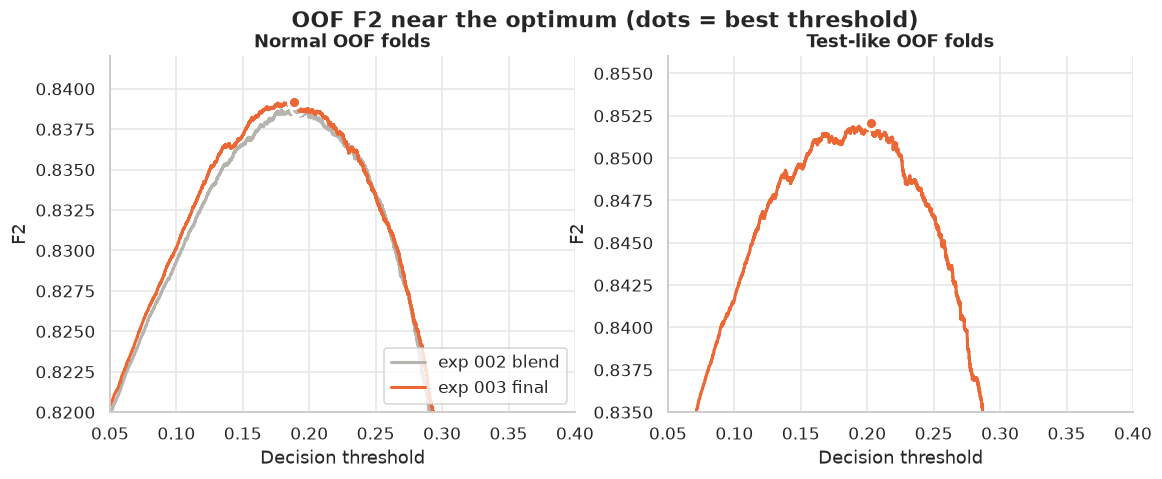

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (title, preds, weight) in zip(axes, [("Normal OOF folds", (p002, oof_final), None),
                                              ("Test-like OOF folds", (None, oof_final_tl), w_testlike)]):
    for name, p, color in [("exp 002 blend", preds[0], NEUTRAL), ("exp 003 final", preds[1], MAIN)]:
        if p is None:
            continue
        thr, f2, _, _ = f2_curve(y, p, weight)
        ax.plot(thr, f2, color=color, linewidth=2, label=name)
        i = np.argmax(f2)
        ax.plot(thr[i], f2[i], "o", color=color, markersize=8, markeredgecolor="white", markeredgewidth=2)
    ax.set(title=title, xlabel="Decision threshold", ylabel="F2", xlim=(0.05, 0.4))
axes[0].set_ylim(0.82, 0.842)
axes[1].set_ylim(0.835, 0.856)
axes[0].legend(loc="lower right")
fig.suptitle("OOF F2 near the optimum (dots = best threshold)", fontweight="bold")
save_fig(fig, "f2-threshold-curves")
plt.show()

## 9. Save OOF predictions

In [28]:
oof_out = pd.DataFrame({ID_COL: lab[ID_COL], "fold": fold_id, TARGET: y, "oof_final": oof_final, "oof_final_testlike": oof_final_tl})
oof_out.to_csv(PRED_DIR / "oof.csv", index=False)
print(f"saved {(PRED_DIR / 'oof.csv').relative_to(TASK_DIR)}  {oof_out.shape}")

saved predictions/experiments/003/oof.csv  (90816, 5)


## 10. Submission

Threshold: tuned on the normal OOF predictions. The test-like threshold is printed as a check.

In [29]:
SUBMIT_THRESHOLD, submit_f2 = best_threshold(y, oof_final)
tl_threshold, _ = best_threshold(y, oof_final_tl, w_testlike)
print(f"threshold {SUBMIT_THRESHOLD:.4f} (OOF F2 {submit_f2:.4f})   test-like threshold {tl_threshold:.4f}")

threshold 0.1882 (OOF F2 0.8392)   test-like threshold 0.2025


Refit all nine members on **all** labeled rows and save them. The test set is used only for prediction.

In [30]:
final_models = [lgbm(params, seed=s, max_bin=4095).fit(X[KEEP], y) for params in CONFIGS for s in SEEDS]
joblib.dump(final_models, MODEL_DIR / "lightgbm.joblib")
joblib.dump({"features": KEEP, "configs": CONFIGS, "seeds": SEEDS, "threshold": SUBMIT_THRESHOLD}, MODEL_DIR / "meta.joblib")
test_proba = np.mean([m.predict_proba(test[KEEP])[:, 1] for m in final_models], axis=0)
pd.DataFrame({ID_COL: test[ID_COL], "proba": test_proba}).to_csv(PRED_DIR / "test.csv", index=False)
print("saved", sorted(p.name for p in MODEL_DIR.iterdir()), "and", (PRED_DIR / "test.csv").relative_to(TASK_DIR))

saved ['lightgbm.joblib', 'meta.joblib'] and predictions/experiments/003/test.csv


In [31]:
print(f"flagged on OOF          : {(oof_final >= SUBMIT_THRESHOLD).mean():.3f}")
print(f"flagged on test-like OOF: {np.average(oof_final_tl >= SUBMIT_THRESHOLD, weights=w_testlike):.3f}")
print(f"flagged on test         : {(test_proba >= SUBMIT_THRESHOLD).mean():.3f}")

flagged on OOF          : 0.634
flagged on test-like OOF: 0.598
flagged on test         : 0.600


Write `submit/index.csv` (`id,task1`). Test row *i* maps to the *i*-th sample id. Compare with the experiment 002 test labels.

In [32]:
sample = pd.read_csv(TASK_DIR.parent / "submission" / "sample_submission.csv", usecols=["id"])
assert len(sample) == len(test)
prev = pd.read_csv(TASK_DIR / "predictions" / "experiments" / "002" / "test.csv")["proba_Blend"].to_numpy() >= 0.19099363226413701
submit = pd.DataFrame({"id": sample["id"], "task1": (test_proba >= SUBMIT_THRESHOLD).astype(int)})
SUBMIT_PATH = TASK_DIR / "submit" / "index.csv"
submit.to_csv(SUBMIT_PATH, index=False)
changed = prev != submit["task1"].to_numpy().astype(bool)
print(f"saved {SUBMIT_PATH.relative_to(TASK_DIR)}  rows {len(submit):,}  share of 1s {submit.task1.mean():.3f}  "
      f"changed vs exp 002: {changed.sum():,} ({changed.mean():.1%})")

saved submit/index.csv  rows 25,889  share of 1s 0.600  changed vs exp 002: 217 (0.8%)


## 11. Conclusion

| Model | OOF ROC AUC | Nested F2 | Test-like F2 | Threshold |
|---|---|---|---|---|
| LightGBM default (exp 001) | 0.8905 | 0.8364 | 0.8492 | 0.195 |
| Blend (exp 002) | 0.8933 | 0.8382 | **0.8518** | 0.191 |
| **LightGBM, 15 features, top-3 configs × 3 seeds (exp 003)** | **0.8938** | **0.8388** | 0.8510 | 0.188 |

**Findings**

- **Task 1 is at its ceiling.** The data is synthetic: the strong features come from piecewise-uniform class densities
  (section 3). Inside the overlap of every range, a value carries no class information. About 23,500 labeled rows sit there at a
  flat ~40% cheater rate, and the F2 threshold must flag all of them. This is Bayes error, not model error.
- **The learning curve confirms it.** 18k → 36k → 73k training rows give F2 0.8327 → 0.8360 → 0.8381. Each doubling adds about
  half of the previous gain, so even double the data would add only about +0.002.
- **No leaks.** IDs, row order, NaN counts, float precision, and labels in the class-only ranges are all clean.
- **Ablations (section 5) are all inside the fold noise (std ≈ 0.0014)**: feature drop, lps range features, and soft
  pseudo-labels are within ±0.001 of each other. Test-like training weights are worse (−0.001 nested, −0.002 test-like).
  The latent-class stacking probe is clearly worse (−0.006).
- **Tuning is flat.** All non-`extra_trees` Optuna trials land at AUC 0.892–0.894. `extra_trees` hurts badly (AUC 0.856–0.878),
  because random split points miss the exact range edges.
- **Exp 003 vs exp 002 is a tie.** Nested F2 +0.0005 (better on 4 of 5 folds, mean per-fold gain +0.0005), test-like F2 −0.0008.
  Both gaps are smaller than the fold noise. Exp 003 is the simpler model: one family, 15 features, no blend weights.
- **Expect a leaderboard F2 near 0.85**, above CV, because test has far fewer NaNs in the strong features
  (77% of test rows have all five block features, vs 42% of train). The flagged share on test (0.600) matches the
  test-like OOF share (0.598), so the threshold transfers.

**Submission:** the exp 003 ensemble refit on all labeled rows, threshold 0.188 → `submit/index.csv`. It flags 60.0% of
test rows and changes 217 labels (0.8%) vs experiment 002.

**Recommendation:** stop model work on Task 1. More time here buys at most about +0.001–0.002 F2. Spend it on tasks with more headroom.